# **Traffic Sign Classification Using Deep Learning**






# **1. Business Case, Problem Statement and Objectives**

**Business case (from the project document):** develop a machine learning model that works on images. The project goal is **image preprocessing** and an **ML model to predict the traffic sign**.

> *Note:* the Business Case line in the project document mentions predicting the "Gender of a person in the frame". This looks like a copy-paste mistake from another project, because the project goal and the data are about traffic signs. This project follows the **project goal and the data**.

**Why it matters:** driver-assistance systems and self-driving cars must recognise road signs (speed limits, stop, give way, and so on) quickly and correctly.

**Problem statement:** given a photo of a traffic sign, predict which sign it is. This is a **multi-class image classification** problem.

**Objectives**
1. Download the dataset and inspect its real folder structure.
2. Clean and preprocess the images (check for corrupt files, duplicates, resize and convert to one format).
3. Explore the data (class distribution, sample images, image sizes).
4. Split into train, validation and test sets with no overlap.
5. Build a CNN from scratch and a MobileNetV2 transfer-learning model.
6. Evaluate on unseen test data with accuracy, top-5 accuracy, macro F1, confusion matrix and per-class results.
7. Save the best model and demonstrate a prediction on a new image.

# **2. Setup: Libraries and Settings**
**What it does:** loads the libraries, fixes the random seed so results can be repeated, and checks whether a GPU is available.  
**Expected output:** the TensorFlow version and `GPU available: True` on a GPU runtime.  
**If the GPU says False:** change the runtime type to GPU and run everything again.

In [2]:
import os, re, json, random, hashlib, zipfile, urllib.request, shutil, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print('TensorFlow version:', tf.__version__)
print('GPU available     :', len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow version: 2.21.0
,GPU available     : True


In [3]:
# ---------- Settings (change only here) ----------
QUICK_TEST = False          # keep False for the real run
DATA_URL   = 'https://d3ilbtxij3aepc.cloudfront.net/projects/AI-Capstone-Projects/PRAICP-1002-TrafSignDetc.zip'
ZIP_PATH   = 'PRAICP-1002-TrafSignDetc.zip'
EXTRACT_DIR = 'traffic_data'
PROC_DIR   = 'processed_images'
IMG_SIZE   = 96             # all images are resized to IMG_SIZE x IMG_SIZE
BATCH      = 64
MIN_PER_CLASS = 10          # classes with fewer images than this cannot be split safely

EPOCHS_CNN = 2 if QUICK_TEST else 25
EPOCHS_TL  = 1 if QUICK_TEST else 8     # transfer learning: frozen stage
EPOCHS_FT  = 1 if QUICK_TEST else 10    # transfer learning: fine-tuning stage
WEIGHTS    = None if QUICK_TEST else 'imagenet'
AUTOTUNE   = tf.data.AUTOTUNE
os.makedirs('outputs', exist_ok=True)

# **3. Download and Extract the Dataset**
**What it does:** downloads the zip file from the project document link and unzips it into the folder `traffic_data`. It skips the download if the file is already there.  
**Expected output:** the file size in MB and `Extraction complete`.  
**If the download fails:** check your internet and run again. If you get 403/404, the link may have expired, so tell your mentor.

In [4]:
if not os.path.exists(ZIP_PATH):
    print('Downloading...')
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
print('Zip size: %.1f MB' % (os.path.getsize(ZIP_PATH) / 1e6))

if not os.path.isdir(EXTRACT_DIR):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)
print('Extraction complete')

Downloading...
,Zip size: 641.6 MB
,Extraction complete


# **4. Inspect the Real Folder Structure**
**What it does:** walks through the extracted folders and prints how many sub-folders and files each one has, and which file types exist. The labels are **not assumed**: the next section reads them from this real structure.  
**What to check:** are there one folder per traffic sign? Is everything an image (`.jpg`, `.png`, `.ppm`...)? Are there extra files such as `.csv`?  
**Report use:** take a screenshot of this output for *Dataset Description*.

In [5]:
ext_counter = Counter()
for root, dirs, files in os.walk(EXTRACT_DIR):
    if '__MACOSX' in root: continue
    for f in files:
        ext_counter[os.path.splitext(f)[1].lower()] += 1
print('File types found:', dict(ext_counter))
print()

lines = 0
for root, dirs, files in os.walk(EXTRACT_DIR):
    if '__MACOSX' in root: continue
    depth = root[len(EXTRACT_DIR):].count(os.sep)
    if depth <= 2 and lines < 60:
        print('  ' * depth + os.path.basename(root) + '/', '->', len(dirs), 'subfolders,', len(files), 'files')
        lines += 1
if lines >= 60: print('... (output shortened)')

File types found: {'.csv': 5, '.png': 103764, '.ods#': 4}
,
,traffic_data/ -> 6 subfolders, 3 files
,  meta/ -> 0 subfolders, 45 files
,  train/ -> 43 subfolders, 0 files
,    4/ -> 0 subfolders, 1980 files
,    21/ -> 0 subfolders, 330 files
,    6/ -> 0 subfolders, 420 files
,    36/ -> 0 subfolders, 390 files
,    38/ -> 0 subfolders, 2070 files
,    17/ -> 0 subfolders, 1110 files
,    32/ -> 0 subfolders, 240 files
,    18/ -> 0 subfolders, 1200 files
,    30/ -> 0 subfolders, 450 files
,    12/ -> 0 subfolders, 2100 files
,    9/ -> 0 subfolders, 1470 files
,    8/ -> 0 subfolders, 1410 files
,    23/ -> 0 subfolders, 510 files
,    40/ -> 0 subfolders, 360 files
,    20/ -> 0 subfolders, 360 files
,    10/ -> 0 subfolders, 2010 files
,    22/ -> 0 subfolders, 390 files
,    35/ -> 0 subfolders, 1200 files
,    14/ -> 0 subfolders, 780 files
,    41/ -> 0 subfolders, 240 files
,    37/ -> 0 subfolders, 210 files
,    26/ -> 0 subfolders, 600 files
,    28/ -> 0 subfolders, 540 fi

# **5. Build the Image Table (Labels from Folder Names)**
**What it does:** finds every image file and uses the **name of the folder it sits in** as its label (the folder-per-class layout described in the project document). The result is a table with one row per image.  
**Why:** a table makes counting, cleaning and splitting easy.  
**What to check:** the number of classes and images should match the folder inspection above. If you see only **1** class, the images are not in class folders. Then check the folder output above and tell your mentor or me.

In [6]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.ppm', '.gif', '.webp', '.tif', '.tiff'}
natural = lambda s: [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', s)]

rows = []
for root, dirs, files in os.walk(EXTRACT_DIR):
    if '__MACOSX' in root: continue
    for f in files:
        if os.path.splitext(f)[1].lower() in IMG_EXT:
            rows.append((os.path.join(root, f), os.path.basename(root)))
df = pd.DataFrame(rows, columns=['path', 'label'])

print('Total image files:', len(df))
print('Number of classes:', df.label.nunique())
if df.label.nunique() < 2:
    print('WARNING: only one label found, so the images are not in class folders. Check the folder structure above.')
print('First class names:', sorted(df.label.unique(), key=natural)[:15])
df.head()

Total image files: 103764
,Number of classes: 47
,First class names: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14']


,path,label
0,traffic_data/meta/0.png,meta
1,traffic_data/meta/10.png,meta
2,traffic_data/meta/33.png,meta
3,traffic_data/meta/4.png,meta
4,traffic_data/meta/15.png,meta


# **6. Image Preprocessing and Data Audit**
**This is the "image preprocessing" goal of the project.** For every image, this step:
1. checks that the file opens (corrupt files are removed),
2. records the original width and height,
3. converts it to **RGB** (3 colour channels),
4. resizes it to **96 x 96** and saves it as a PNG in `processed_images/`,
5. computes a fingerprint (MD5) so **exact duplicate images** can be found.

**Why:** models need all images in one size and format. Duplicates, especially with different labels, can mislead training and make the test score unfairly high when copies land in both train and test.  
**Duplicate rule:** the same image appearing under **two different labels** is removed completely (the label is unreliable). Exact duplicates with the same label keep only one copy.

In [7]:
shutil.rmtree(PROC_DIR, ignore_errors=True)
records, bad = [], []
for i, (p, l) in enumerate(tqdm(zip(df.path, df.label), total=len(df))):
    try:
        with open(p, 'rb') as fh:
            md5 = hashlib.md5(fh.read()).hexdigest()
        im = Image.open(p); im.load()
        w, h = im.size
        im = im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        safe = re.sub(r'[^\w\-]', '_', l)
        out_dir = os.path.join(PROC_DIR, safe); os.makedirs(out_dir, exist_ok=True)
        out_path = os.path.join(out_dir, f'{i}.png'); im.save(out_path)
        records.append(dict(path=p, proc_path=out_path, label=l, width=w, height=h, md5=md5))
    except Exception as e:
        bad.append((p, str(e)[:80]))

full = pd.DataFrame(records)
print('Images processed OK :', len(full))
print('Corrupt/unreadable  :', len(bad), bad[:3])

# duplicates
n_labels_per_hash = full.groupby('md5')['label'].nunique()
conflict_hashes = n_labels_per_hash[n_labels_per_hash > 1].index
n_conflict = int(full.md5.isin(conflict_hashes).sum())
clean = full[~full.md5.isin(conflict_hashes)]
n_dups = int(clean.duplicated('md5', keep='first').sum())
clean = clean.drop_duplicates('md5', keep='first')
print('Same image under different labels (removed):', n_conflict)
print('Exact duplicates, same label (extra copies removed):', n_dups)

# very small classes
counts = clean.label.value_counts()
small = counts[counts < MIN_PER_CLASS]
if len(small):
    print('Classes removed (fewer than %d images):' % MIN_PER_CLASS, dict(small))
    clean = clean[~clean.label.isin(small.index)]

df = clean.reset_index(drop=True)
class_names = sorted(df.label.unique(), key=natural)
cls2id = {c: i for i, c in enumerate(class_names)}
df['y'] = df.label.map(cls2id)
N_CLASSES = len(class_names)
print('\nAfter cleaning: %d images, %d classes (removed %d in total)' % (len(df), N_CLASSES, len(full) - len(df)))

  0%|          | 0/103764 [00:00<?, ?it/s]

Images processed OK : 103764
,Corrupt/unreadable  : 0 []
,Same image under different labels (removed): 25362
,Exact duplicates, same label (extra copies removed): 39201
,
,After cleaning: 39201 images, 43 classes (removed 64563 in total)


**Note on the cleaning numbers above (please read):** the large numbers do **not** mean the data was dirty. The extracted zip contains the same files several times: the training images appear in both the `train/` and `Train/` folders, the test images appear in both `Test/` and `test/` (12,630 images each), and `meta/` holds one reference picture per sign. Because images are labelled by folder name, these copies created 47 labels (the 43 real sign classes plus `meta`, `Meta`, `Test` and `test`) and the same image under several labels. The cleaning step removed them automatically.

What remains is **39,201 unique training images in the 43 real sign classes**. The 43 training folders contain 39,209 images in total, so 8 genuine exact duplicates were also removed. The separate `Test` folder was **not** used: the test set in this notebook is a random 15% of the training images.


# **7. Exploratory Data Analysis (EDA)**
**What it does:** shows how many images each class has, sample images, and the original image sizes.  
**What to look for:** a big gap between the largest and smallest class means **class imbalance**. Very different image sizes are the reason we resize everything.  
**Report use:** screenshots of the bar chart, the sample grid and the size histogram go in *EDA*.  
*The printed "Insight" lines below are calculated from your real data.*

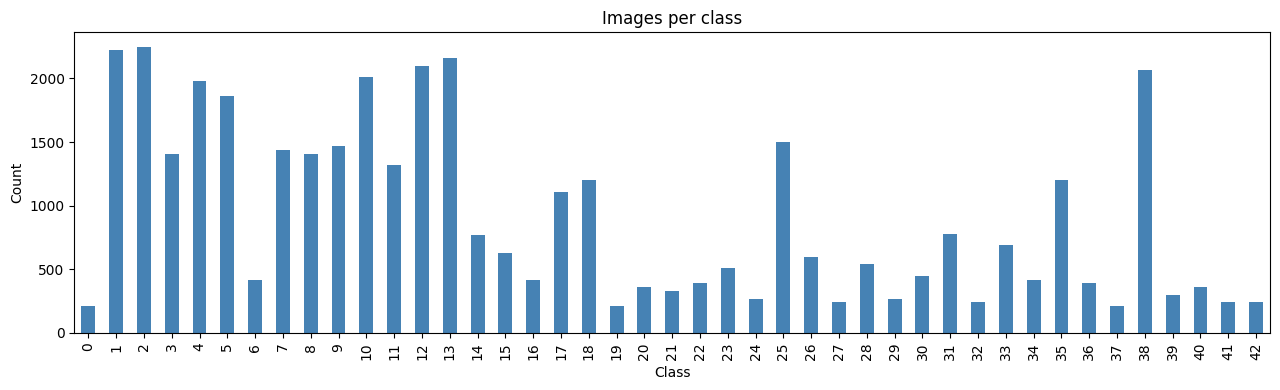

Insight: largest class "2" has 2250 images, smallest class "0" has 210 images (ratio 10.7 : 1).
,Insight: the dataset is clearly imbalanced, so class weights will be used.


In [8]:
counts = df.label.value_counts().reindex(class_names)
fig, ax = plt.subplots(figsize=(max(8, N_CLASSES * 0.3), 4))
counts.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Images per class'); ax.set_xlabel('Class'); ax.set_ylabel('Count')
plt.tight_layout(); plt.show()

ratio = counts.max() / counts.min()
print('Insight: largest class "%s" has %d images, smallest class "%s" has %d images (ratio %.1f : 1).'
      % (counts.idxmax(), counts.max(), counts.idxmin(), counts.min(), ratio))
print('Insight: the dataset is %s.' % ('clearly imbalanced, so class weights will be used' if ratio > 2 else 'fairly balanced'))

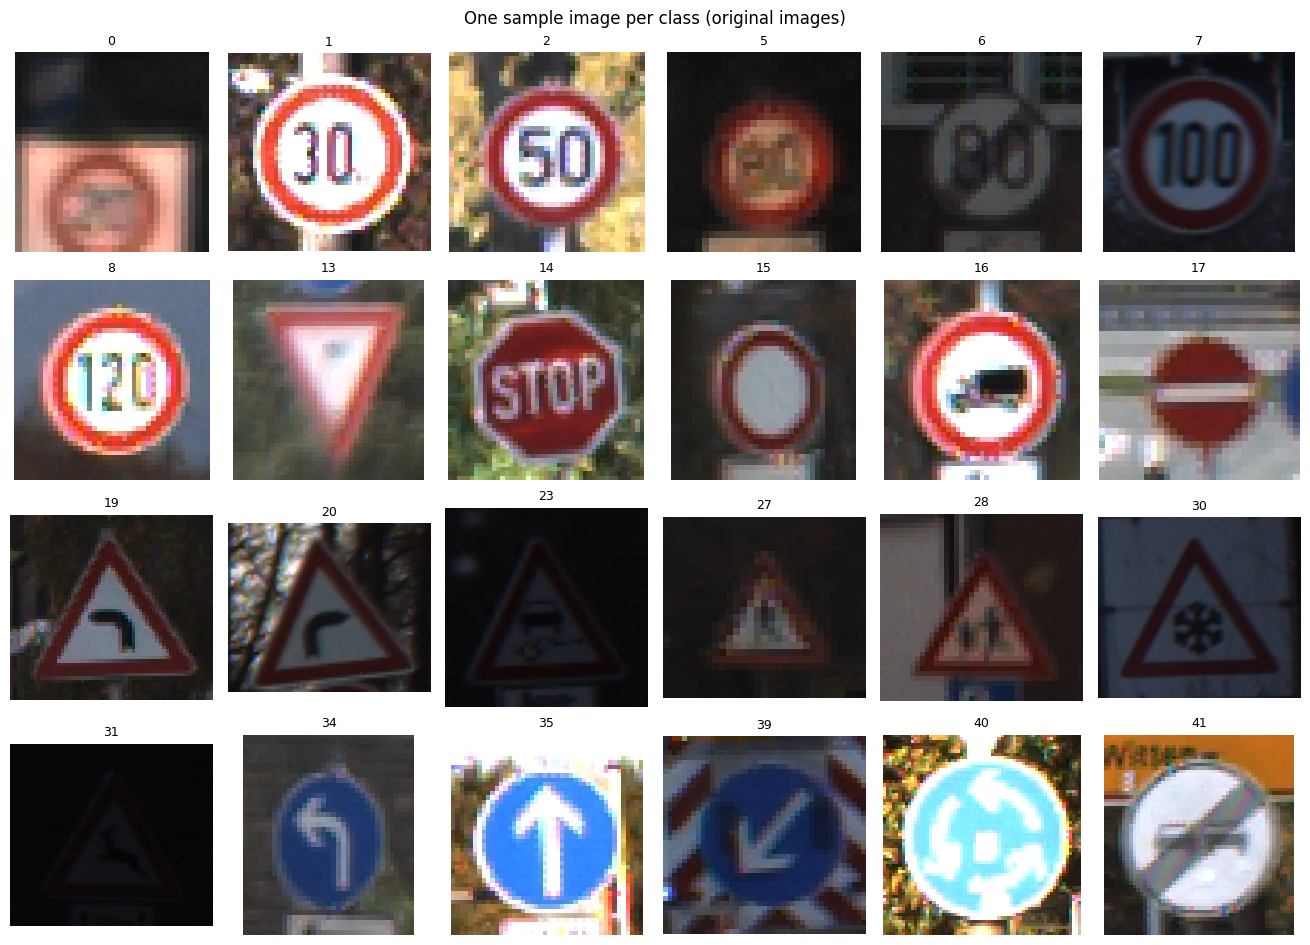

In [9]:
# one random example from each of up to 24 classes
show = class_names if N_CLASSES <= 24 else sorted(random.sample(class_names, 24), key=natural)
cols = 6; rows_n = int(np.ceil(len(show) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 2.2, rows_n * 2.4))
for ax in np.array(axes).ravel(): ax.axis('off')
for ax, c in zip(np.array(axes).ravel(), show):
    r = df[df.label == c].sample(1, random_state=SEED).iloc[0]
    ax.imshow(Image.open(r.path).convert('RGB')); ax.set_title(str(c), fontsize=9)
plt.suptitle('One sample image per class (original images)'); plt.tight_layout(); plt.show()

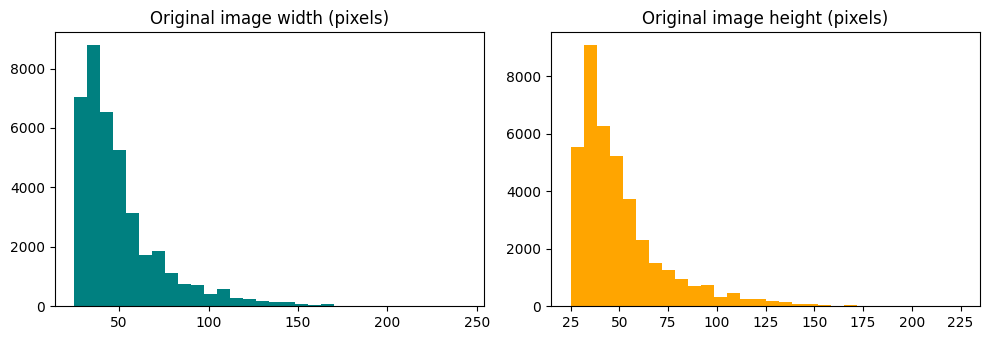

Insight: original width ranges from 25 to 243 px (median 43); height from 25 to 225 px (median 43).
,So all images are resized to 96x96.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df.width, bins=30, color='teal');  axes[0].set_title('Original image width (pixels)')
axes[1].hist(df.height, bins=30, color='orange'); axes[1].set_title('Original image height (pixels)')
plt.tight_layout(); plt.show()
print('Insight: original width ranges from %d to %d px (median %d); height from %d to %d px (median %d).'
      % (df.width.min(), df.width.max(), df.width.median(), df.height.min(), df.height.max(), df.height.median()))
print('So all images are resized to %dx%d.' % (IMG_SIZE, IMG_SIZE))

# **8. Train / Validation / Test Split (No Leakage)**
**What it does:** splits the cleaned images **70% train / 15% validation / 15% test**, keeping the same class proportions in each part (stratified).  
**Why:** the model learns on *train*, we choose settings and the best model with *validation*, and the *test* set is used **only once at the end** to measure real performance. Because exact duplicates were removed earlier, the same image cannot be in two parts. The check below confirms zero overlap.

In [11]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.y, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df.y, random_state=SEED)

print('Train: %d | Validation: %d | Test: %d' % (len(train_df), len(val_df), len(test_df)))
for n_, a_, b_ in [('train/val', train_df, val_df), ('train/test', train_df, test_df), ('val/test', val_df, test_df)]:
    print('Overlap %-10s files: %d | identical images: %d'
          % (n_, len(set(a_.path) & set(b_.path)), len(set(a_.md5) & set(b_.md5))))

cw = compute_class_weight('balanced', classes=np.arange(N_CLASSES), y=train_df.y.values)
class_weight = dict(enumerate(cw))
print('Class weights range: %.2f to %.2f' % (cw.min(), cw.max()))

Train: 27440 | Validation: 5880 | Test: 5881
,Overlap train/val  files: 0 | identical images: 0
,Overlap train/test files: 0 | identical images: 0
,Overlap val/test   files: 0 | identical images: 0
,Class weights range: 0.41 to 4.34


# **9. Input Pipeline and Data Augmentation**
**Input pipeline (`tf.data`):** reads the processed images from disk in batches, so we never load all images into memory at once.  
**Augmentation:** small random rotation, zoom, shift and contrast change, applied **only during training** so the model sees more variety.  
**Important:** we do **not** flip images left-right. A flipped traffic sign can change its meaning (for example a "turn left" sign becomes "turn right").

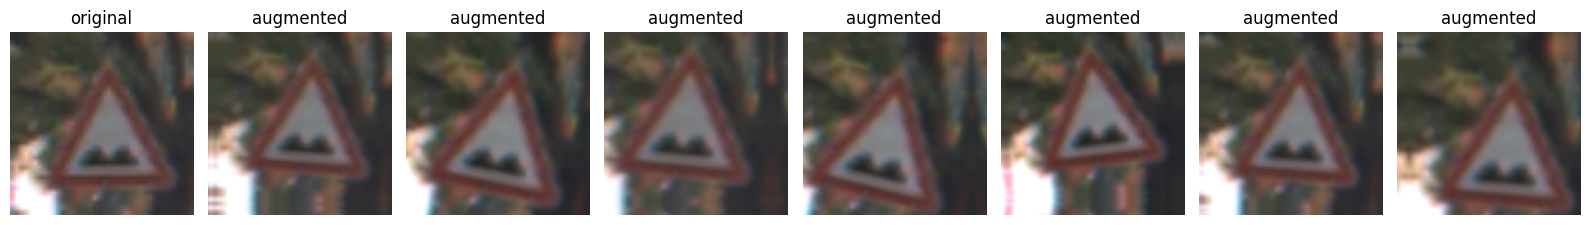

In [12]:
def decode(path, label):
    img = tf.io.decode_png(tf.io.read_file(path), channels=3)
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return tf.cast(img, tf.float32), label

def make_ds(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame.proc_path.values, frame.y.values.astype('int32')))
    if training: ds = ds.shuffle(len(frame), seed=SEED)
    return ds.map(decode, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

augment = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomContrast(0.20),
], name='augmentation')

# preview: one training image and 7 augmented versions
x_batch, _ = next(iter(train_ds))
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(x_batch[0].numpy().astype('uint8')); axes[0].set_title('original'); axes[0].axis('off')
for k in range(1, 8):
    axes[k].imshow(augment(x_batch[:1], training=True)[0].numpy().clip(0, 255).astype('uint8'))
    axes[k].set_title('augmented'); axes[k].axis('off')
plt.tight_layout(); plt.show()

# **10. Helper Functions: Training Curves and Evaluation**
**What it does:** defines reusable functions used for every model:
- `plot_history`: plots training vs validation accuracy and loss (to spot overfitting).
- `evaluate_model`: predicts on the **test set** and reports accuracy, **top-5 accuracy** (is the right sign among the model's 5 best guesses), **macro F1** (average F1 over all classes, so small classes count equally), the full classification report, and saves the model.  
  It also records the **validation** accuracy, which is used later to choose the best model (so the test set is **not** used for choosing).

In [13]:
results, test_probs, val_scores = {}, {}, {}
TOPK = min(5, N_CLASSES)
COMPILE_METRICS = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=TOPK, name='top_k')]

def plot_history(histories, title):
    h = {}
    for hist in histories:
        for k, v in hist.history.items(): h.setdefault(k, []).extend(v)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(h['accuracy'], label='train'); ax[0].plot(h['val_accuracy'], label='validation')
    ax[0].set_title(title + ': accuracy'); ax[0].set_xlabel('epoch'); ax[0].legend()
    ax[1].plot(h['loss'], label='train'); ax[1].plot(h['val_loss'], label='validation')
    ax[1].set_title(title + ': loss'); ax[1].set_xlabel('epoch'); ax[1].legend()
    plt.tight_layout(); plt.show()
    gap = h['accuracy'][-1] - h['val_accuracy'][-1]
    print('Final train accuracy %.4f | final validation accuracy %.4f | gap %.4f' % (h['accuracy'][-1], h['val_accuracy'][-1], gap))

def evaluate_model(model, name):
    probs = model.predict(test_ds, verbose=0)
    y_true, y_pred = test_df.y.values, probs.argmax(1)
    topk_idx = np.argsort(probs, axis=1)[:, -TOPK:]
    r = dict(Accuracy=accuracy_score(y_true, y_pred),
             TopK_Accuracy=float(np.mean([t in row for t, row in zip(y_true, topk_idx)])),
             Macro_F1=f1_score(y_true, y_pred, average='macro', zero_division=0))
    results[name], test_probs[name] = r, probs
    val_scores[name] = model.evaluate(val_ds, verbose=0, return_dict=True)['accuracy']
    model.save('outputs/' + re.sub(r'\W+', '_', name) + '.keras')
    print('=====', name, ': TEST SET RESULTS =====')
    print(classification_report(y_true, y_pred, labels=list(range(N_CLASSES)), target_names=[str(c) for c in class_names],
                                zero_division=0, digits=4))
    print('Accuracy %.4f | Top-%d accuracy %.4f | Macro F1 %.4f' % (r['Accuracy'], TOPK, r['TopK_Accuracy'], r['Macro_F1']))

callbacks = lambda: [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6),
]

# **11. Model 1: CNN Built From Scratch (Baseline)**
**What the layers do:**
- **Rescaling** turns pixel values 0-255 into 0-1.
- **Conv2D** layers learn shapes (edges, circles, arrows). **BatchNormalization** keeps training stable. **MaxPooling** shrinks the image and keeps the strongest signals.
- **GlobalAveragePooling** + **Dropout** reduce overfitting.
- The last **Dense** layer with **softmax** gives one probability per traffic-sign class.

**Training helpers:** early stopping (stop when validation loss stops improving), learning-rate reduction, and class weights for imbalance.  
**Report use:** `model.summary()` goes in *CNN Model Design*; the curves go in *Model Training and Validation*.

In [14]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

def build_cnn():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1. / 255)(inp)
    x = augment(x)
    for f in (32, 64, 128, 256): x = conv_block(x, f)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(N_CLASSES, activation='softmax')(x)
    return models.Model(inp, out, name='cnn_from_scratch')

cnn_model = build_cnn()
cnn_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=COMPILE_METRICS)
cnn_model.summary()

Model: "cnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,186,187 (4.52 MB)

 Trainable params: 1,184,267 (4.52 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/25
,429/429 - 63s - 146ms/step - accuracy: 0.1233 - loss: 3.0975 - top_k: 0.4027 - val_accuracy: 0.1128 - val_loss: 3.0397 - val_top_k: 0.4876 - learning_rate: 0.0010
,Epoch 2/25
,429/429 - 50s - 115ms/step - accuracy: 0.3273 - loss: 2.0763 - top_k: 0.7403 - val_accuracy: 0.4264 - val_loss: 1.6980 - val_top_k: 0.8350 - learning_rate: 0.0010
,Epoch 3/25
,429/429 - 50s - 117ms/step - accuracy: 0.6907 - loss: 0.9111 - top_k: 0.9570 - val_accuracy: 0.7765 - val_loss: 0.7276 - val_top_k: 0.9857 - learning_rate: 0.0010
,Epoch 4/25
,429/429 - 52s - 122ms/step - accuracy: 0.9213 - loss: 0.2595 - top_k: 0.9951 - val_accuracy: 0.9430 - val_loss: 0.2496 - val_top_k: 0.9961 - learning_rate: 0.0010
,Epoch 5/25
,429/429 - 51s - 118ms/step - accuracy: 0.9701 - loss: 0.1051 - top_k: 0.9984 - val_accuracy: 0.9884 - val_loss: 0.0755 - val_top_k: 0.9993 - learning_rate: 0.0010
,Epoch 6/25
,429/429 - 50s - 118ms/step - accuracy: 0.9786 - loss: 0.0775 - top_k: 0.9989 - val_accuracy: 0.9903 - val_lo

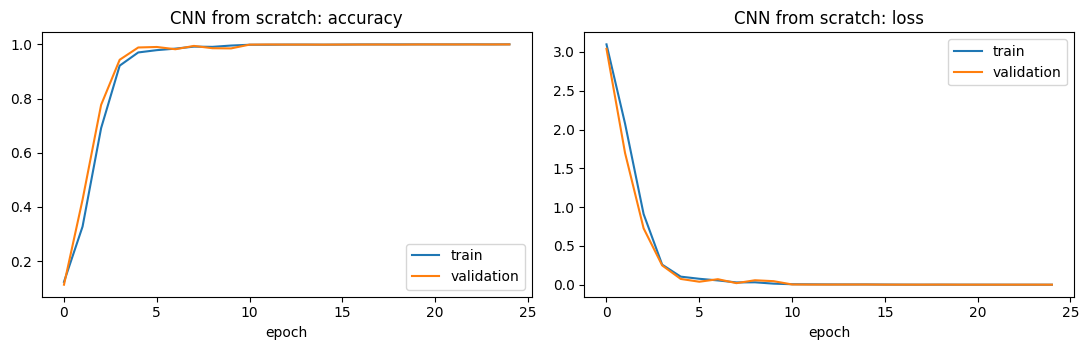

Final train accuracy 1.0000 | final validation accuracy 0.9998 | gap 0.0002


In [15]:
t0 = time.time()
history_cnn = cnn_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_CNN,
                            class_weight=class_weight, callbacks=callbacks(), verbose=2)
print('Training time: %.1f min | epochs run: %d' % ((time.time() - t0) / 60, len(history_cnn.history['loss'])))
plot_history([history_cnn], 'CNN from scratch')

In [16]:
evaluate_model(cnn_model, 'CNN from scratch')

===== CNN from scratch : TEST SET RESULTS =====
,              precision    recall  f1-score   support
,
,           0     1.0000    1.0000    1.0000        31
,           1     1.0000    1.0000    1.0000       333
,           2     1.0000    1.0000    1.0000       338
,           3     1.0000    1.0000    1.0000       212
,           4     1.0000    1.0000    1.0000       297
,           5     1.0000    1.0000    1.0000       279
,           6     1.0000    1.0000    1.0000        63
,           7     1.0000    1.0000    1.0000       216
,           8     1.0000    1.0000    1.0000       212
,           9     1.0000    1.0000    1.0000       221
,          10     1.0000    1.0000    1.0000       302
,          11     1.0000    1.0000    1.0000       198
,          12     0.9968    1.0000    0.9984       315
,          13     1.0000    1.0000    1.0000       324
,          14     1.0000    1.0000    1.0000       116
,          15     1.0000    1.0000    1.0000        95
,          16  

# **12. Model 2: MobileNetV2 Transfer Learning**
**Idea:** MobileNetV2 was already trained on millions of everyday photos (ImageNet). We reuse what it learned and train only a new top layer for our traffic signs.  
**Stage 1 (frozen):** the pretrained part is locked; only the new classifier learns.  
**Stage 2 (fine-tuning):** the last 30 layers are unlocked and trained with a very small learning rate, so the model adapts a little more to signs.  
**Note:** the pretrained weights come from the internet the first time. If that download is blocked, set `WEIGHTS = None` in the settings (the model then trains from random weights and will usually be worse).

,9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
,Epoch 1/8
,429/429 - 24s - 55ms/step - accuracy: 0.4917 - loss: 1.6990 - top_k: 0.8589 - val_accuracy: 0.7253 - val_loss: 0.8538 - val_top_k: 0.9626 - learning_rate: 0.0010
,Epoch 2/8
,429/429 - 16s - 38ms/step - accuracy: 0.6826 - loss: 0.9053 - top_k: 0.9553 - val_accuracy: 0.7711 - val_loss: 0.6795 - val_top_k: 0.9796 - learning_rate: 0.0010
,Epoch 3/8
,429/429 - 16s - 38ms/step - accuracy: 0.7266 - loss: 0.7399 - top_k: 0.9677 - val_accuracy: 0.7869 - val_loss: 0.6266 - val_top_k: 0.9816 - learning_rate: 0.0010
,Epoch 4/8
,429/429 - 20s - 48ms/step - accuracy: 0.7520 - loss: 0.6486 - top_k: 0.9751 - val_accuracy: 0.8112 - val_loss: 0.5532 - val_top_k: 0.9872 - learning_rate: 0.0010
,Epoch 5/8
,429/429 - 16s - 37ms/step - accuracy: 0.7650 - loss: 0.5998 - top_k: 0.9793 - val_accuracy: 0.8112 - val_loss: 0.5467 - val_top_k: 0.9874 - learning_rate: 0.0010
,Epoch 6/8
,429/429 - 19s - 44ms/step - accuracy: 0.7774 - loss: 0.5641 - top_k:

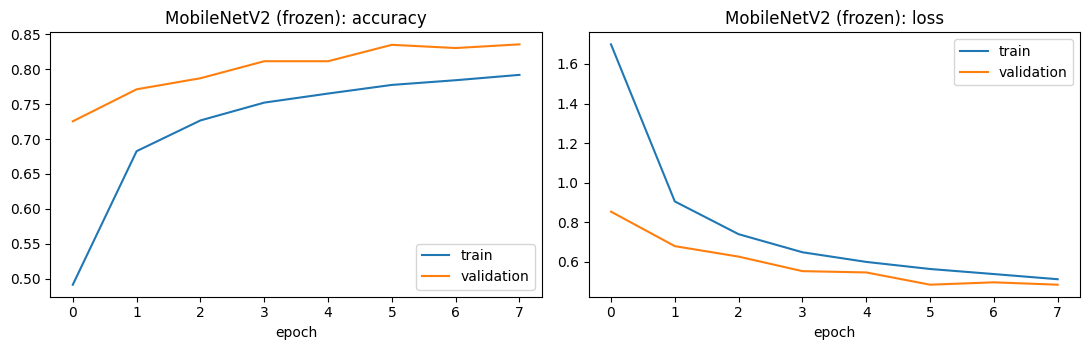

Final train accuracy 0.7917 | final validation accuracy 0.8354 | gap -0.0436


In [17]:
base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights=WEIGHTS)
base.trainable = False

inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
x = augment(inp)
x = layers.Rescaling(1. / 127.5, offset=-1)(x)          # MobileNetV2 expects values in [-1, 1]
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(N_CLASSES, activation='softmax')(x)
tl_model = models.Model(inp, out, name='mobilenetv2_transfer')
tl_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=COMPILE_METRICS)

t0 = time.time()
history_tl1 = tl_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_TL,
                           class_weight=class_weight, callbacks=callbacks(), verbose=2)
print('Stage 1 time: %.1f min' % ((time.time() - t0) / 60))
plot_history([history_tl1], 'MobileNetV2 (frozen)')

In [18]:
evaluate_model(tl_model, 'MobileNetV2 (frozen)')

===== MobileNetV2 (frozen) : TEST SET RESULTS =====
,              precision    recall  f1-score   support
,
,           0     0.5000    0.8387    0.6265        31
,           1     0.8346    0.6366    0.7223       333
,           2     0.7169    0.6893    0.7029       338
,           3     0.7953    0.6415    0.7102       212
,           4     0.7879    0.7003    0.7415       297
,           5     0.7000    0.6774    0.6885       279
,           6     1.0000    0.9524    0.9756        63
,           7     0.4988    0.9722    0.6593       216
,           8     0.8129    0.5330    0.6439       212
,           9     0.9469    0.8869    0.9159       221
,          10     0.8716    0.9437    0.9062       302
,          11     0.8993    0.6768    0.7723       198
,          12     0.9968    0.9905    0.9936       315
,          13     0.9969    0.9877    0.9922       324
,          14     1.0000    1.0000    1.0000       116
,          15     0.9792    0.9895    0.9843        95
,          

Epoch 1/10
,429/429 - 29s - 68ms/step - accuracy: 0.8206 - loss: 0.4312 - top_k: 0.9880 - val_accuracy: 0.8558 - val_loss: 0.4251 - val_top_k: 0.9918 - learning_rate: 1.0000e-05
,Epoch 2/10
,429/429 - 20s - 48ms/step - accuracy: 0.8406 - loss: 0.3658 - top_k: 0.9907 - val_accuracy: 0.8646 - val_loss: 0.4024 - val_top_k: 0.9918 - learning_rate: 1.0000e-05
,Epoch 3/10
,429/429 - 21s - 49ms/step - accuracy: 0.8514 - loss: 0.3292 - top_k: 0.9924 - val_accuracy: 0.8806 - val_loss: 0.3495 - val_top_k: 0.9942 - learning_rate: 1.0000e-05
,Epoch 4/10
,429/429 - 20s - 47ms/step - accuracy: 0.8637 - loss: 0.3030 - top_k: 0.9938 - val_accuracy: 0.8866 - val_loss: 0.3414 - val_top_k: 0.9942 - learning_rate: 1.0000e-05
,Epoch 5/10
,429/429 - 21s - 49ms/step - accuracy: 0.8726 - loss: 0.2745 - top_k: 0.9934 - val_accuracy: 0.8910 - val_loss: 0.3227 - val_top_k: 0.9939 - learning_rate: 1.0000e-05
,Epoch 6/10
,429/429 - 41s - 94ms/step - accuracy: 0.8734 - loss: 0.2654 - top_k: 0.9944 - val_accuracy: 0

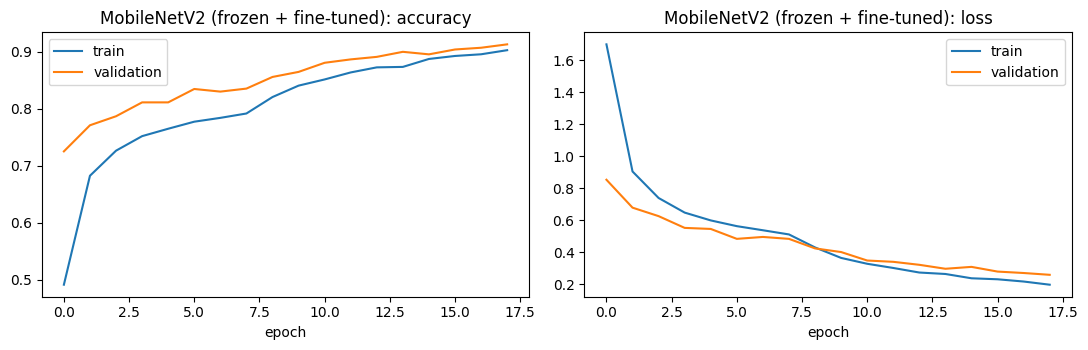

Final train accuracy 0.9027 | final validation accuracy 0.9129 | gap -0.0102


In [19]:
# Stage 2: fine-tune the last 30 layers (BatchNorm layers stay frozen)
base.trainable = True
for layer in base.layers[:-30]: layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization): layer.trainable = False
tl_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='sparse_categorical_crossentropy', metrics=COMPILE_METRICS)

t0 = time.time()
history_tl2 = tl_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT,
                           class_weight=class_weight, callbacks=callbacks(), verbose=2)
print('Stage 2 time: %.1f min' % ((time.time() - t0) / 60))
plot_history([history_tl1, history_tl2], 'MobileNetV2 (frozen + fine-tuned)')

In [20]:
evaluate_model(tl_model, 'MobileNetV2 (fine-tuned)')

===== MobileNetV2 (fine-tuned) : TEST SET RESULTS =====
,              precision    recall  f1-score   support
,
,           0     0.8438    0.8710    0.8571        31
,           1     0.9363    0.7508    0.8333       333
,           2     0.7028    0.8817    0.7822       338
,           3     0.8632    0.7736    0.8159       212
,           4     0.9057    0.7441    0.8170       297
,           5     0.8296    0.8029    0.8160       279
,           6     1.0000    0.9841    0.9920        63
,           7     0.7163    0.9583    0.8198       216
,           8     0.8196    0.7500    0.7833       212
,           9     0.9904    0.9321    0.9604       221
,          10     0.9481    0.9669    0.9574       302
,          11     0.9465    0.8939    0.9195       198
,          12     0.9968    1.0000    0.9984       315
,          13     0.9938    0.9938    0.9938       324
,          14     1.0000    1.0000    1.0000       116
,          15     0.9896    1.0000    0.9948        95
,      

# **13. Model Comparison and Choosing the Best Model**
**What it does:** puts all models side by side on the test set, and picks the best one using the **validation** accuracy (not the test set), so the test set stays an honest final check.  
**Report use:** the table and bar chart go in *Model Evaluation* and *Results*.

,Accuracy,TopK_Accuracy,Macro_F1,Validation_Accuracy
CNN from scratch,0.9998,0.9998,0.9999,0.9998
MobileNetV2 (frozen),0.8349,0.9927,0.8439,0.8354
MobileNetV2 (fine-tuned),0.9145,0.9978,0.9301,0.9129


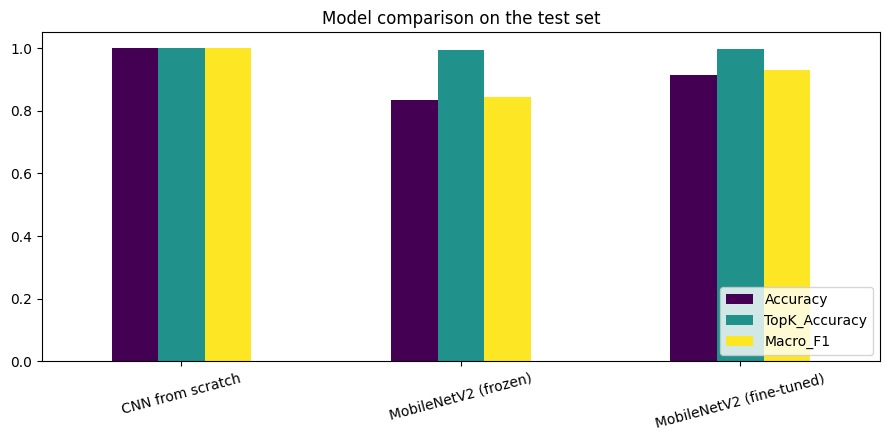

Best model (chosen by validation accuracy): CNN from scratch
,Its test results: {'Accuracy': 0.9998, 'TopK_Accuracy': 0.9998, 'Macro_F1': 0.9999}


In [21]:
res = pd.DataFrame(results).T.round(4)
res['Validation_Accuracy'] = pd.Series(val_scores).round(4)
display(res)

res[['Accuracy', 'TopK_Accuracy', 'Macro_F1']].plot(kind='bar', figsize=(9, 4.5), colormap='viridis')
plt.title('Model comparison on the test set'); plt.ylim(0, 1.05); plt.xticks(rotation=15)
plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

best_name = res['Validation_Accuracy'].idxmax()
print('Best model (chosen by validation accuracy):', best_name)
print('Its test results:', res.loc[best_name, ['Accuracy', 'TopK_Accuracy', 'Macro_F1']].to_dict())

# **14. Confusion Matrix, Weakest Classes and Mistakes of the Best Model**
**Confusion matrix:** rows are the true sign, columns the predicted sign. A bright diagonal means mostly correct. Bright spots off the diagonal are signs the model mixes up.  
**What to look for:** which pairs of signs are confused (often look-alike signs such as different speed limits), and which classes have the lowest F1.  
**Report use:** the matrix, the confusion list and the mistake pictures go in *Results and Visualizations* and *Discussion*.

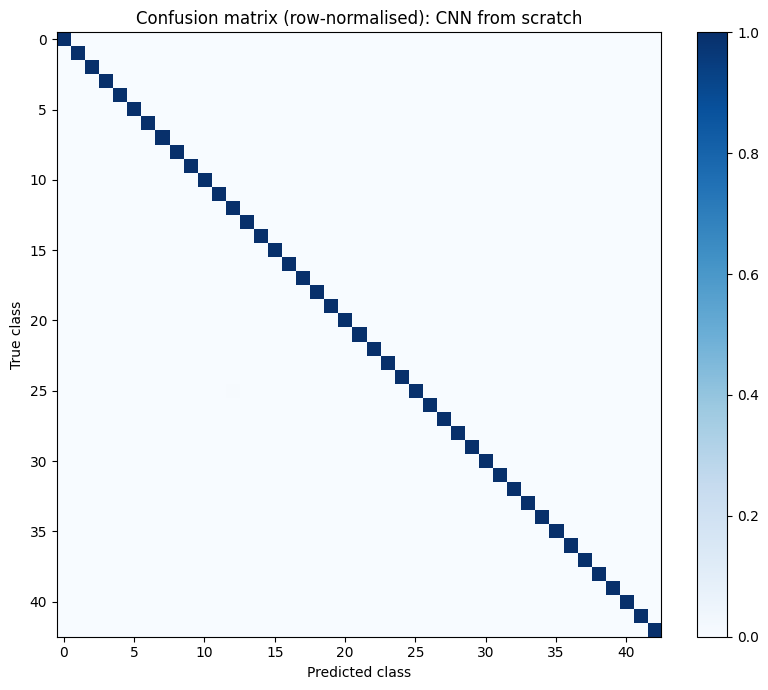

Most frequent confusions (true -> predicted : count):
,  25 -> 12 : 1
,
,5 weakest classes by F1:
,25    0.998
,12    0.998
,2     1.000
,0     1.000
,4     1.000


In [22]:
probs = test_probs[best_name]
y_true, y_pred = test_df.y.values, probs.argmax(1)
cm = confusion_matrix(y_true, y_pred, labels=list(range(N_CLASSES)))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm_norm, cmap='Blues'); plt.colorbar(im, fraction=0.046)
ax.set_title('Confusion matrix (row-normalised): ' + best_name)
ax.set_xlabel('Predicted class'); ax.set_ylabel('True class')
if N_CLASSES <= 20:
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(class_names, rotation=90); ax.set_yticklabels(class_names)
plt.tight_layout(); plt.show()

# most frequent confusions
pairs = [(cm[i, j], class_names[i], class_names[j]) for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j and cm[i, j] > 0]
pairs.sort(reverse=True)
print('Most frequent confusions (true -> predicted : count):')
for c_, a_, b_ in pairs[:10]: print('  %s -> %s : %d' % (a_, b_, c_))
if not pairs: print('  none, the model made no mistakes on the test set')

# weakest classes by F1
rep = classification_report(y_true, y_pred, labels=list(range(N_CLASSES)), target_names=[str(c) for c in class_names],
                            zero_division=0, output_dict=True)
f1s = pd.Series({c: rep[str(c)]['f1-score'] for c in class_names}).sort_values()
print('\n5 weakest classes by F1:'); print(f1s.head(5).round(3).to_string())

Total test images: 5881 | wrongly classified: 1 (0.02%)


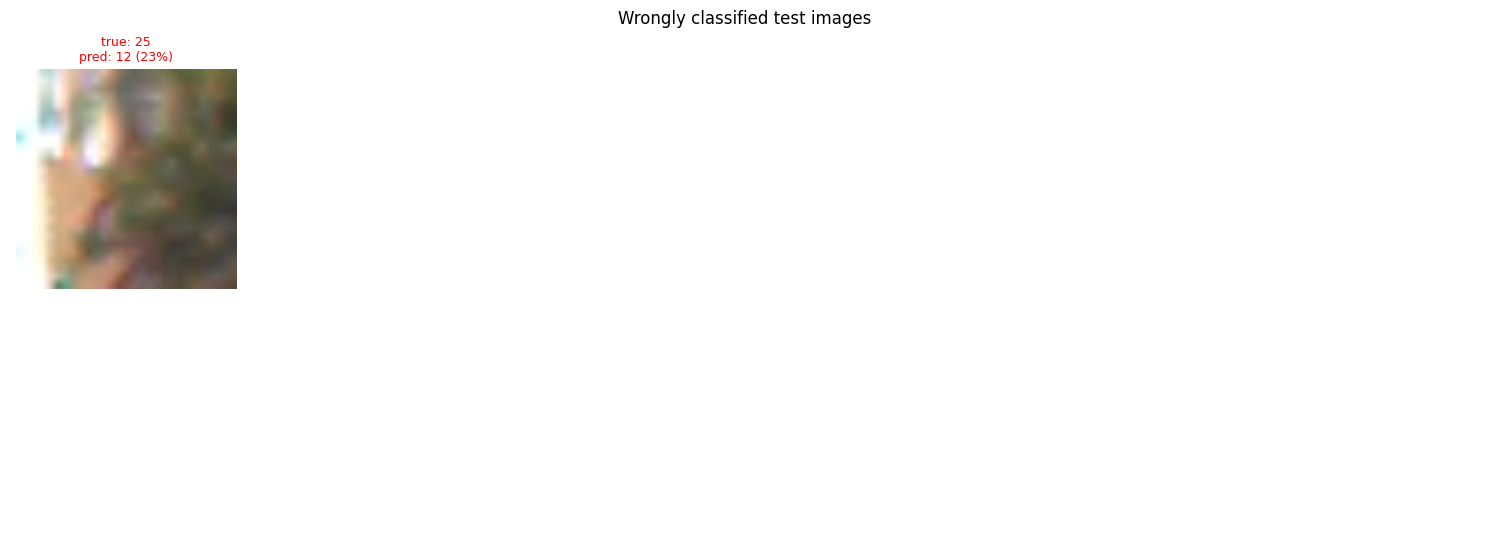

In [23]:
wrong = np.where(y_true != y_pred)[0]
print('Total test images: %d | wrongly classified: %d (%.2f%%)' % (len(y_true), len(wrong), 100 * len(wrong) / len(y_true)))
if len(wrong):
    pick = np.random.RandomState(SEED).choice(wrong, size=min(12, len(wrong)), replace=False)
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
    for ax in axes.ravel(): ax.axis('off')
    for ax, k in zip(axes.ravel(), pick):
        ax.imshow(Image.open(test_df.iloc[k].proc_path))
        ax.set_title('true: %s\npred: %s (%.0f%%)' % (class_names[y_true[k]], class_names[y_pred[k]], 100 * probs[k].max()), fontsize=9, color='red')
    plt.suptitle('Wrongly classified test images'); plt.tight_layout(); plt.show()

# **15. Save the Best Model and Predict a New Image**
**What it does:** saves the best model and the class names, then defines `predict_sign(path)`, which prepares a new image **exactly like the training images** and prints the 3 most likely signs with their probabilities.  
**To test your own image in Colab:** upload a picture of a traffic sign (left sidebar → Files → Upload) and call `predict_sign('your_image.png')`.  
**Reading the output:** a high percentage means the model is confident. It does not guarantee the answer is right.

Saved: outputs/best_traffic_sign_model.keras and outputs/class_names.json
,Actual: 7


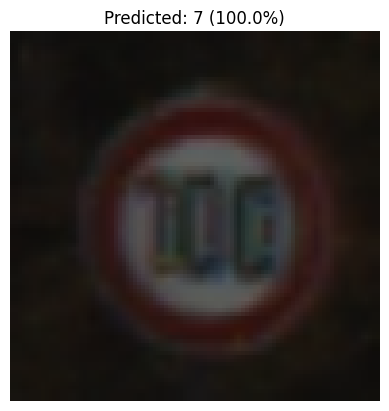

  7            100.00%
,  8            0.00%
,  5            0.00%
,Actual: 41


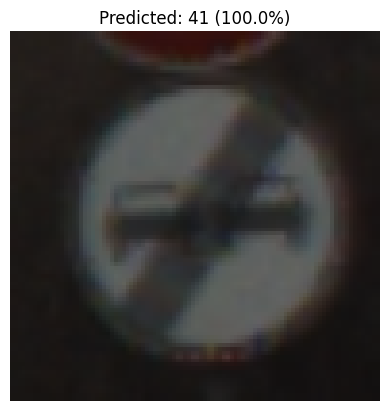

  41           100.00%
,  42           0.00%
,  32           0.00%
,Actual: 2


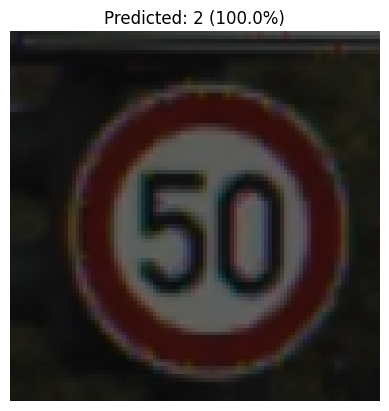

  2            100.00%
,  4            0.00%
,  5            0.00%


In [24]:
best_file = 'outputs/' + re.sub(r'\W+', '_', best_name) + '.keras'
shutil.copy(best_file, 'outputs/best_traffic_sign_model.keras')
json.dump(class_names, open('outputs/class_names.json', 'w'))
print('Saved: outputs/best_traffic_sign_model.keras and outputs/class_names.json')

best_model = tf.keras.models.load_model('outputs/best_traffic_sign_model.keras')

def predict_sign(path, show=True):
    im = Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    p = best_model.predict(np.array(im, dtype='float32')[None], verbose=0)[0]
    top = np.argsort(p)[::-1][:3]
    if show:
        plt.imshow(im); plt.axis('off'); plt.title('Predicted: %s (%.1f%%)' % (class_names[top[0]], 100 * p[top[0]])); plt.show()
    for k in top: print('  %-12s %.2f%%' % (class_names[k], 100 * p[k]))
    return class_names[top[0]]

# demo on 3 random test images (the true label is shown for checking)
for _, r in test_df.sample(3, random_state=SEED).iterrows():
    print('Actual:', r.label); predict_sign(r.path)

# **16. Final Summary**
**What it does:** prints the key numbers of this run in one place. Copy these into the *Abstract*, *Results* and *Conclusion* of your report. Every number is calculated from your run.

In [25]:
b = res.loc[best_name]
print('=' * 62)
print('   FINAL SUMMARY - Traffic Sign Classification (PRAICP-1002)')
print('=' * 62)
print('Images after cleaning : %d  (%d classes)' % (len(df), N_CLASSES))
print('Split                 : Train %d | Validation %d | Test %d' % (len(train_df), len(val_df), len(test_df)))
print('Models compared       :', ', '.join(res.index))
print('Best model (by validation accuracy):', best_name)
print('  Test accuracy       : %.4f' % b['Accuracy'])
print('  Test top-%d accuracy : %.4f' % (TOPK, b['TopK_Accuracy']))
print('  Test macro F1       : %.4f' % b['Macro_F1'])
print('=' * 62)

,   FINAL SUMMARY - Traffic Sign Classification (PRAICP-1002)
,==============================================================
,Images after cleaning : 39201  (43 classes)
,Split                 : Train 27440 | Validation 5880 | Test 5881
,Models compared       : CNN from scratch, MobileNetV2 (frozen), MobileNetV2 (fine-tuned)
,Best model (by validation accuracy): CNN from scratch
,  Test accuracy       : 0.9998
,  Test top-5 accuracy : 0.9998
,  Test macro F1       : 0.9999
,==============================================================


# **17. Conclusion, Limitations and Future Enhancements**

**Conclusion**
- A complete pipeline was built for traffic sign classification: download, structure inspection, preprocessing (RGB conversion, resizing, corrupt-file and duplicate checks), EDA, a leak-free stratified split, augmentation, training, evaluation and saving.
- A CNN built from scratch and a MobileNetV2 transfer-learning model (frozen and fine-tuned) were compared on the same unseen test set. The measured numbers are in the comparison table and the Final Summary above.
- The best model was chosen using validation accuracy, so the test set was only used for the final honest check.
- Because there are many classes, top-k accuracy, macro F1, per-class results and the confusion list were used, not accuracy alone.

**Challenges faced and how they were handled**
1. **Unknown folder layout:** labels were read from the real folder names and printed for checking before training.
2. **Different image sizes and formats:** every image was converted to RGB and resized to 96x96 and saved as PNG.
3. **Class imbalance:** class weights during training, and macro F1 and per-class results during evaluation.
4. **Duplicate and repeated files:** the zip contains copies of the train and test folders. Exact duplicates and the same image under different labels were removed, leaving 39,201 unique images in 43 classes, so train, validation and test cannot share identical files.
5. **Flipping changes meaning:** left-right flip augmentation was deliberately not used.
6. **Memory:** a `tf.data` pipeline reads images batch by batch.

**Limitations**
- **The test score is probably too optimistic.** The CNN reached 0.9998 test accuracy (1 wrong image out of 5,881). Traffic-sign datasets usually contain several nearly identical photos of the same physical sign (for example frames from one video). A random split can put such near-copies in both train and test, so the model may partly be recognising signs it has effectively seen before. Exact-duplicate removal cannot catch near-copies. The zip also has a separate `Test` folder, which was not used here; testing on it would be a harder and fairer check.
- Results come from one dataset. The model was not tested in real driving conditions (night, rain, blur, damaged signs).
- The model classifies a picture of one sign. It does not find signs inside a full road scene (that is object detection).
- This is an academic project. It is **not** a safety-certified driving system.

**Future enhancements**
- Add an object-detection model (for example YOLO) to find signs inside full road images.
- Test on images from other countries, weather and lighting.
- Try larger pretrained models, longer fine-tuning and test-time augmentation.
- Show Grad-CAM heat-maps to see which part of the sign the model uses.